# Binary genetic algorithm: experimental results

The two objective functions are **One-Max** (maximize the number of ones) and **LeadingOnes** (maximize the consecutive prefix of ones). For both problems the optimum is `D`. Each dimension is evaluated over 10 independent runs and a budget of `100 × D` objective-function evaluations.

## Experimental configuration

| Parameter | Value |
|---|---:|
| Dimensions | 10, 30, 100 |
| Independent runs | 10 |
| Population size | 50 |
| Elitism ratio | 0.10 |
| Crossover ratio | 0.90 |
| Mutation probability | 0.01 per bit |
| Parent selection | Rank selection |
| Crossover | Single-point |
| Evaluation budget | `100 × D` |

The mutation probability is within the requested approximate 0.5–1% range. Elitism preserves the best 10% of the population, while rank selection avoids extreme fitness scaling effects.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import Image, display

root = Path.cwd()
results_path = root / "results.json"
if not results_path.exists():
    raise FileNotFoundError(
        f"Expected {results_path}. Run main.py with result saving enabled first. (--save-results flag)"
    )
results = json.loads(results_path.read_text(encoding="utf-8"))
dimensions = [10, 30, 100]
results.keys()

dict_keys(['one-max', 'leading-ones'])

## Summary statistics

The following table reproduces the console output. `best` and `worst` are the final fitness values among the 10 runs; the other columns summarize the distribution.

In [2]:
rows = []
for problem, by_dimension in results.items():
    for dimension in dimensions:
        record = by_dimension[f"D{dimension}"]
        rows.append(
            {
                "Problem": problem,
                "D": dimension,
                "FES budget": record["max_fes"],
                **{key: round(value, 2) for key, value in record["statistics"].items()},
            }
        )
summary = pd.DataFrame(rows)
summary

,Problem,D,FES budget,best,worst,mean,median,stddev
0,one-max,10,1000,10,10,10.0,10.0,0.00
1,one-max,30,3000,30,30,30.0,30.0,0.00
2,one-max,100,10000,100,100,100.0,100.0,0.00
3,leading-ones,10,1000,10,10,10.0,10.0,0.00
4,leading-ones,30,3000,30,19,27.6,30.0,3.72
5,leading-ones,100,10000,78,54,61.5,60.5,6.57


### Interpretation

* **One-Max** reaches the theoretical optimum in every run for every dimension. Every statistic equals `D` and the standard deviation is zero.
* **LeadingOnes** is substantially harder. At `D = 100`, the mean is 61.50 and the standard deviation is 6.57.
* The gap between the LeadingOnes mean and its optimum grows from 2.40 (`D = 30`) and 38.50 (`D = 100`).
* Since only 10 runs were performed, these values are empirical summaries rather than precise estimates of the complete performance distribution.

## Average convergence: One-Max

The curve is the mean of the best-so-far fitness trace over the 10 runs. The horizontal axis counts objective-function evaluations (FES). Curves end at `100 × D`, so larger dimensions receive proportionally larger absolute budgets.

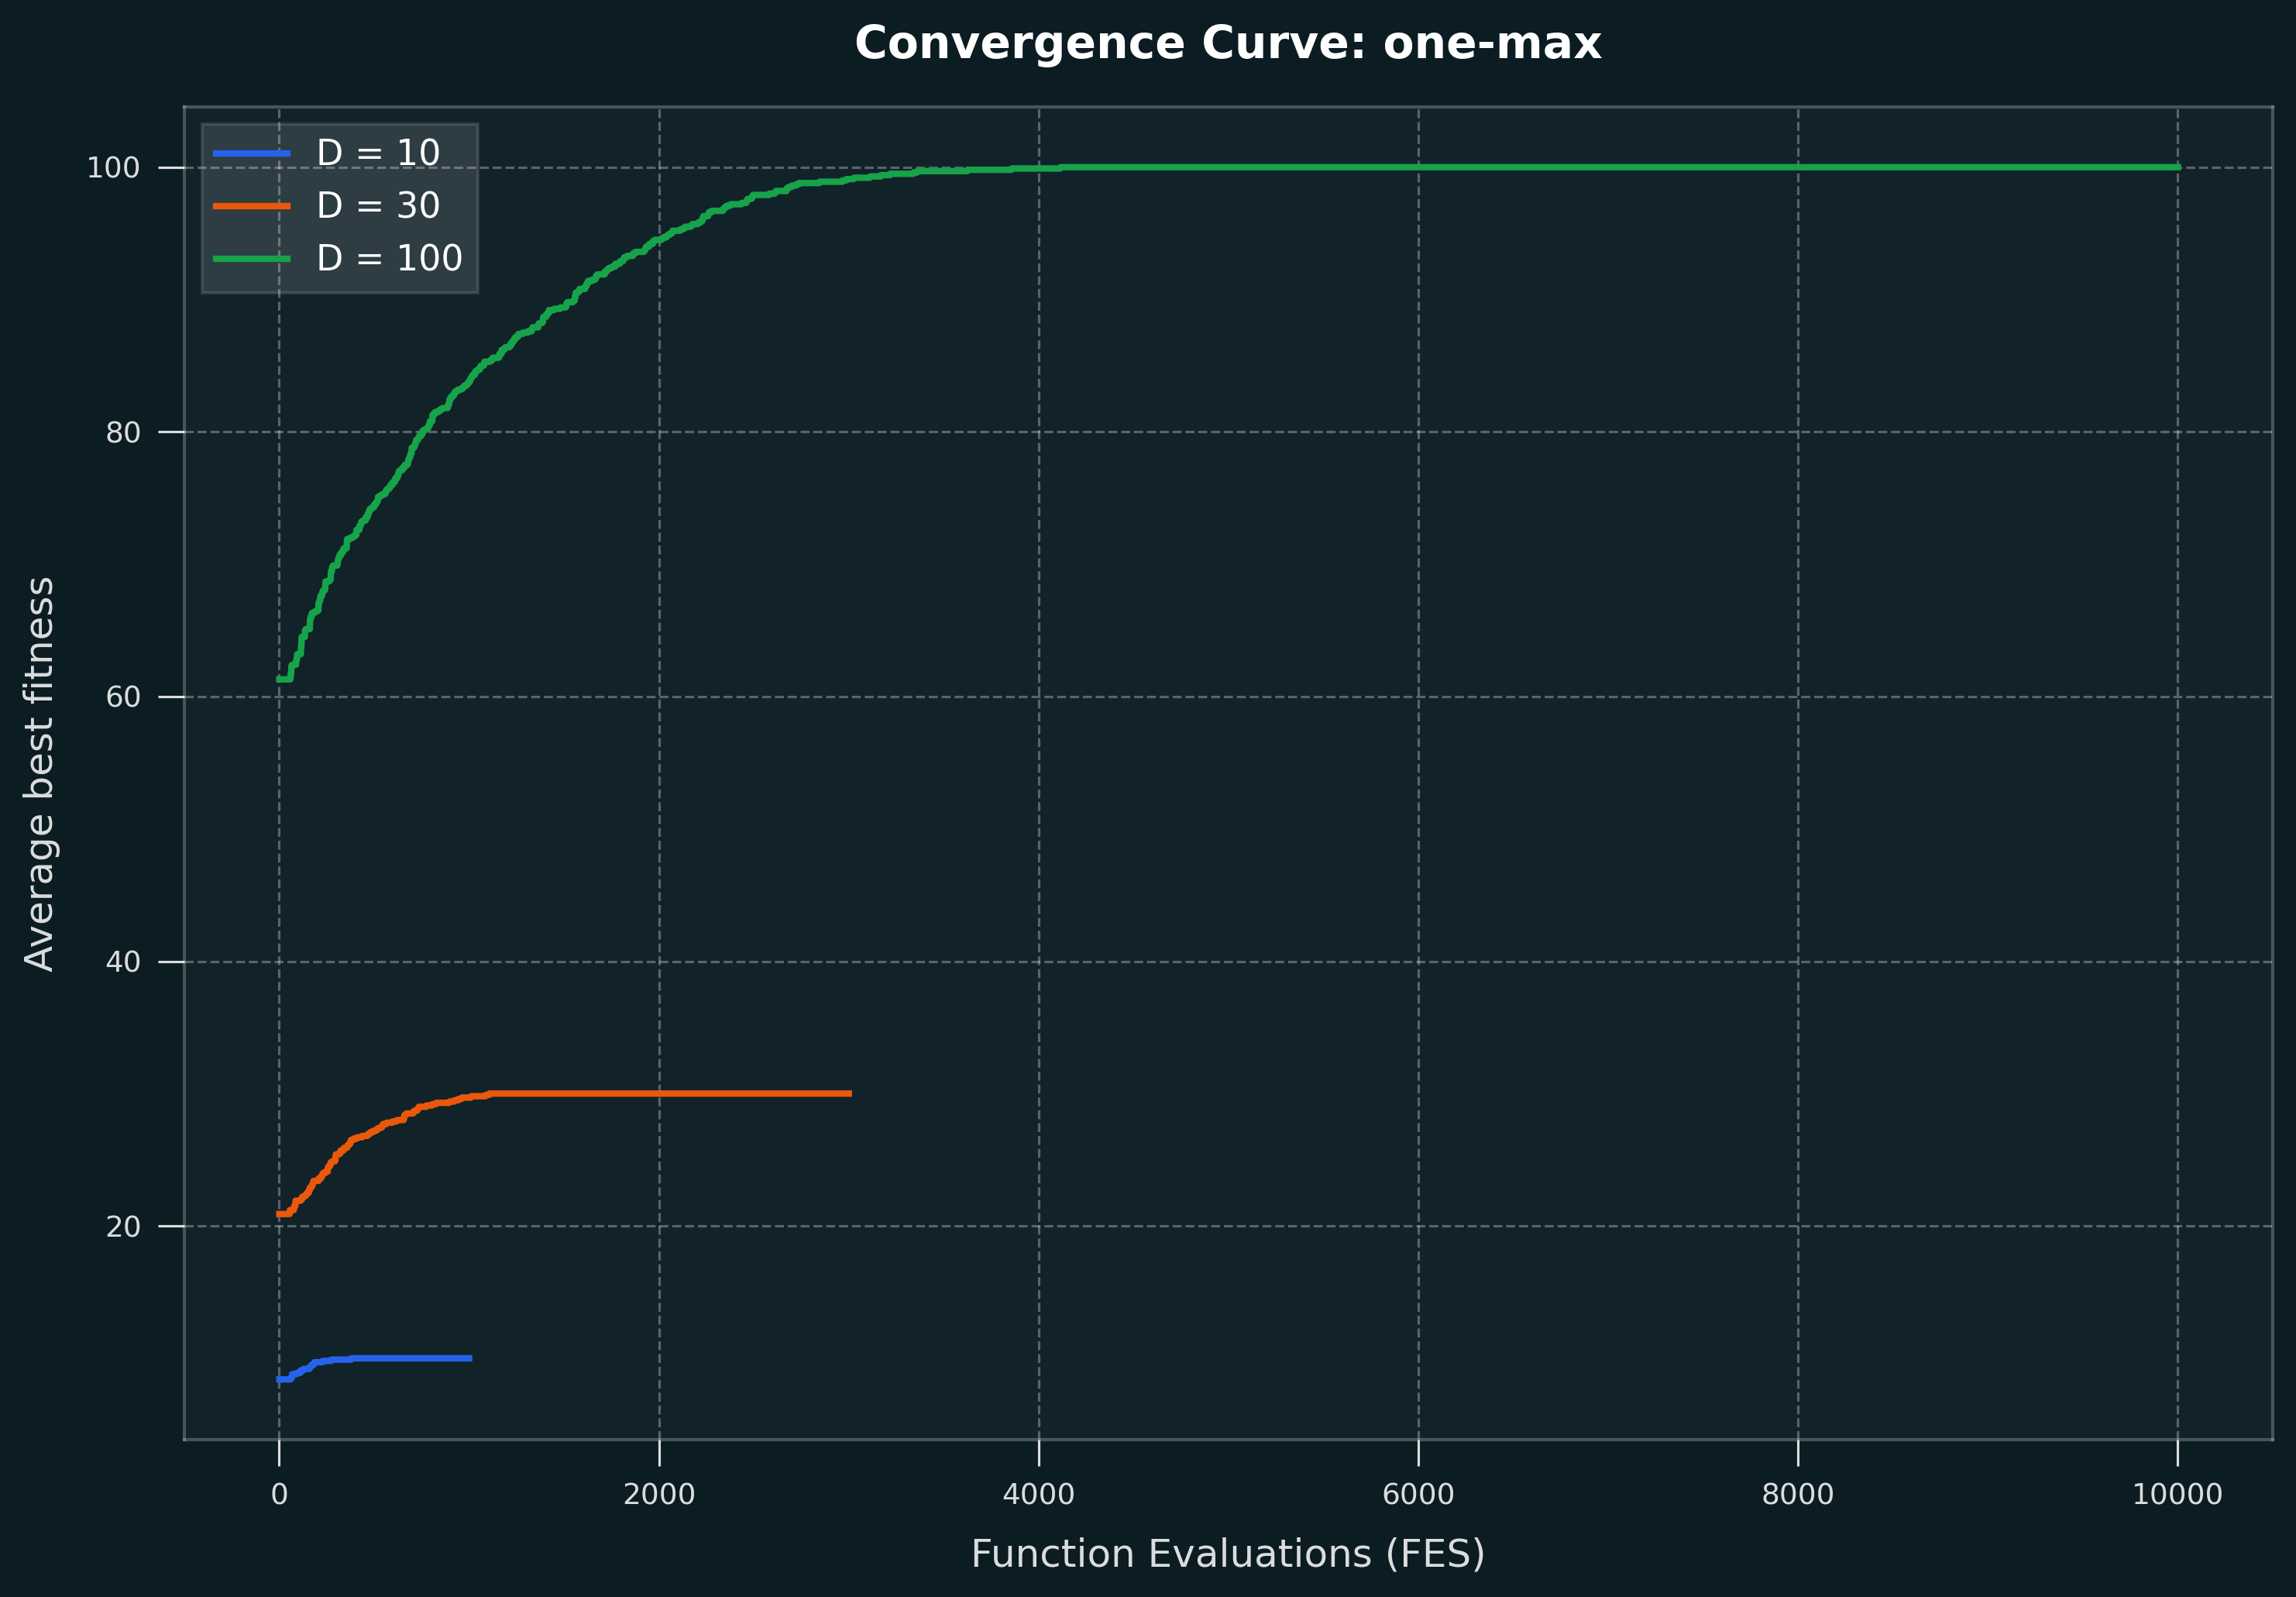

In [3]:
one_max_image = root / "img" / "convergence" / "convergence_one-max.png"
display(Image(filename=str(one_max_image), width=900))

**Explanation.** The One-Max curves rise quickly and then become horizontal when the optimum is found. The `D = 10` and `D = 30` cases converge early, while `D = 100` needs more evaluations but reaches fitness 100 well before the 10,000-FES limit. The monotonic shape is expected because the plotted quantity is best-so-far fitness. The different vertical levels are expected because the optimum itself is dimension-dependent.

## Average convergence: LeadingOnes

LeadingOnes rewards only the uninterrupted prefix of ones. A one after the first zero does not improve the score until all preceding positions are corrected.

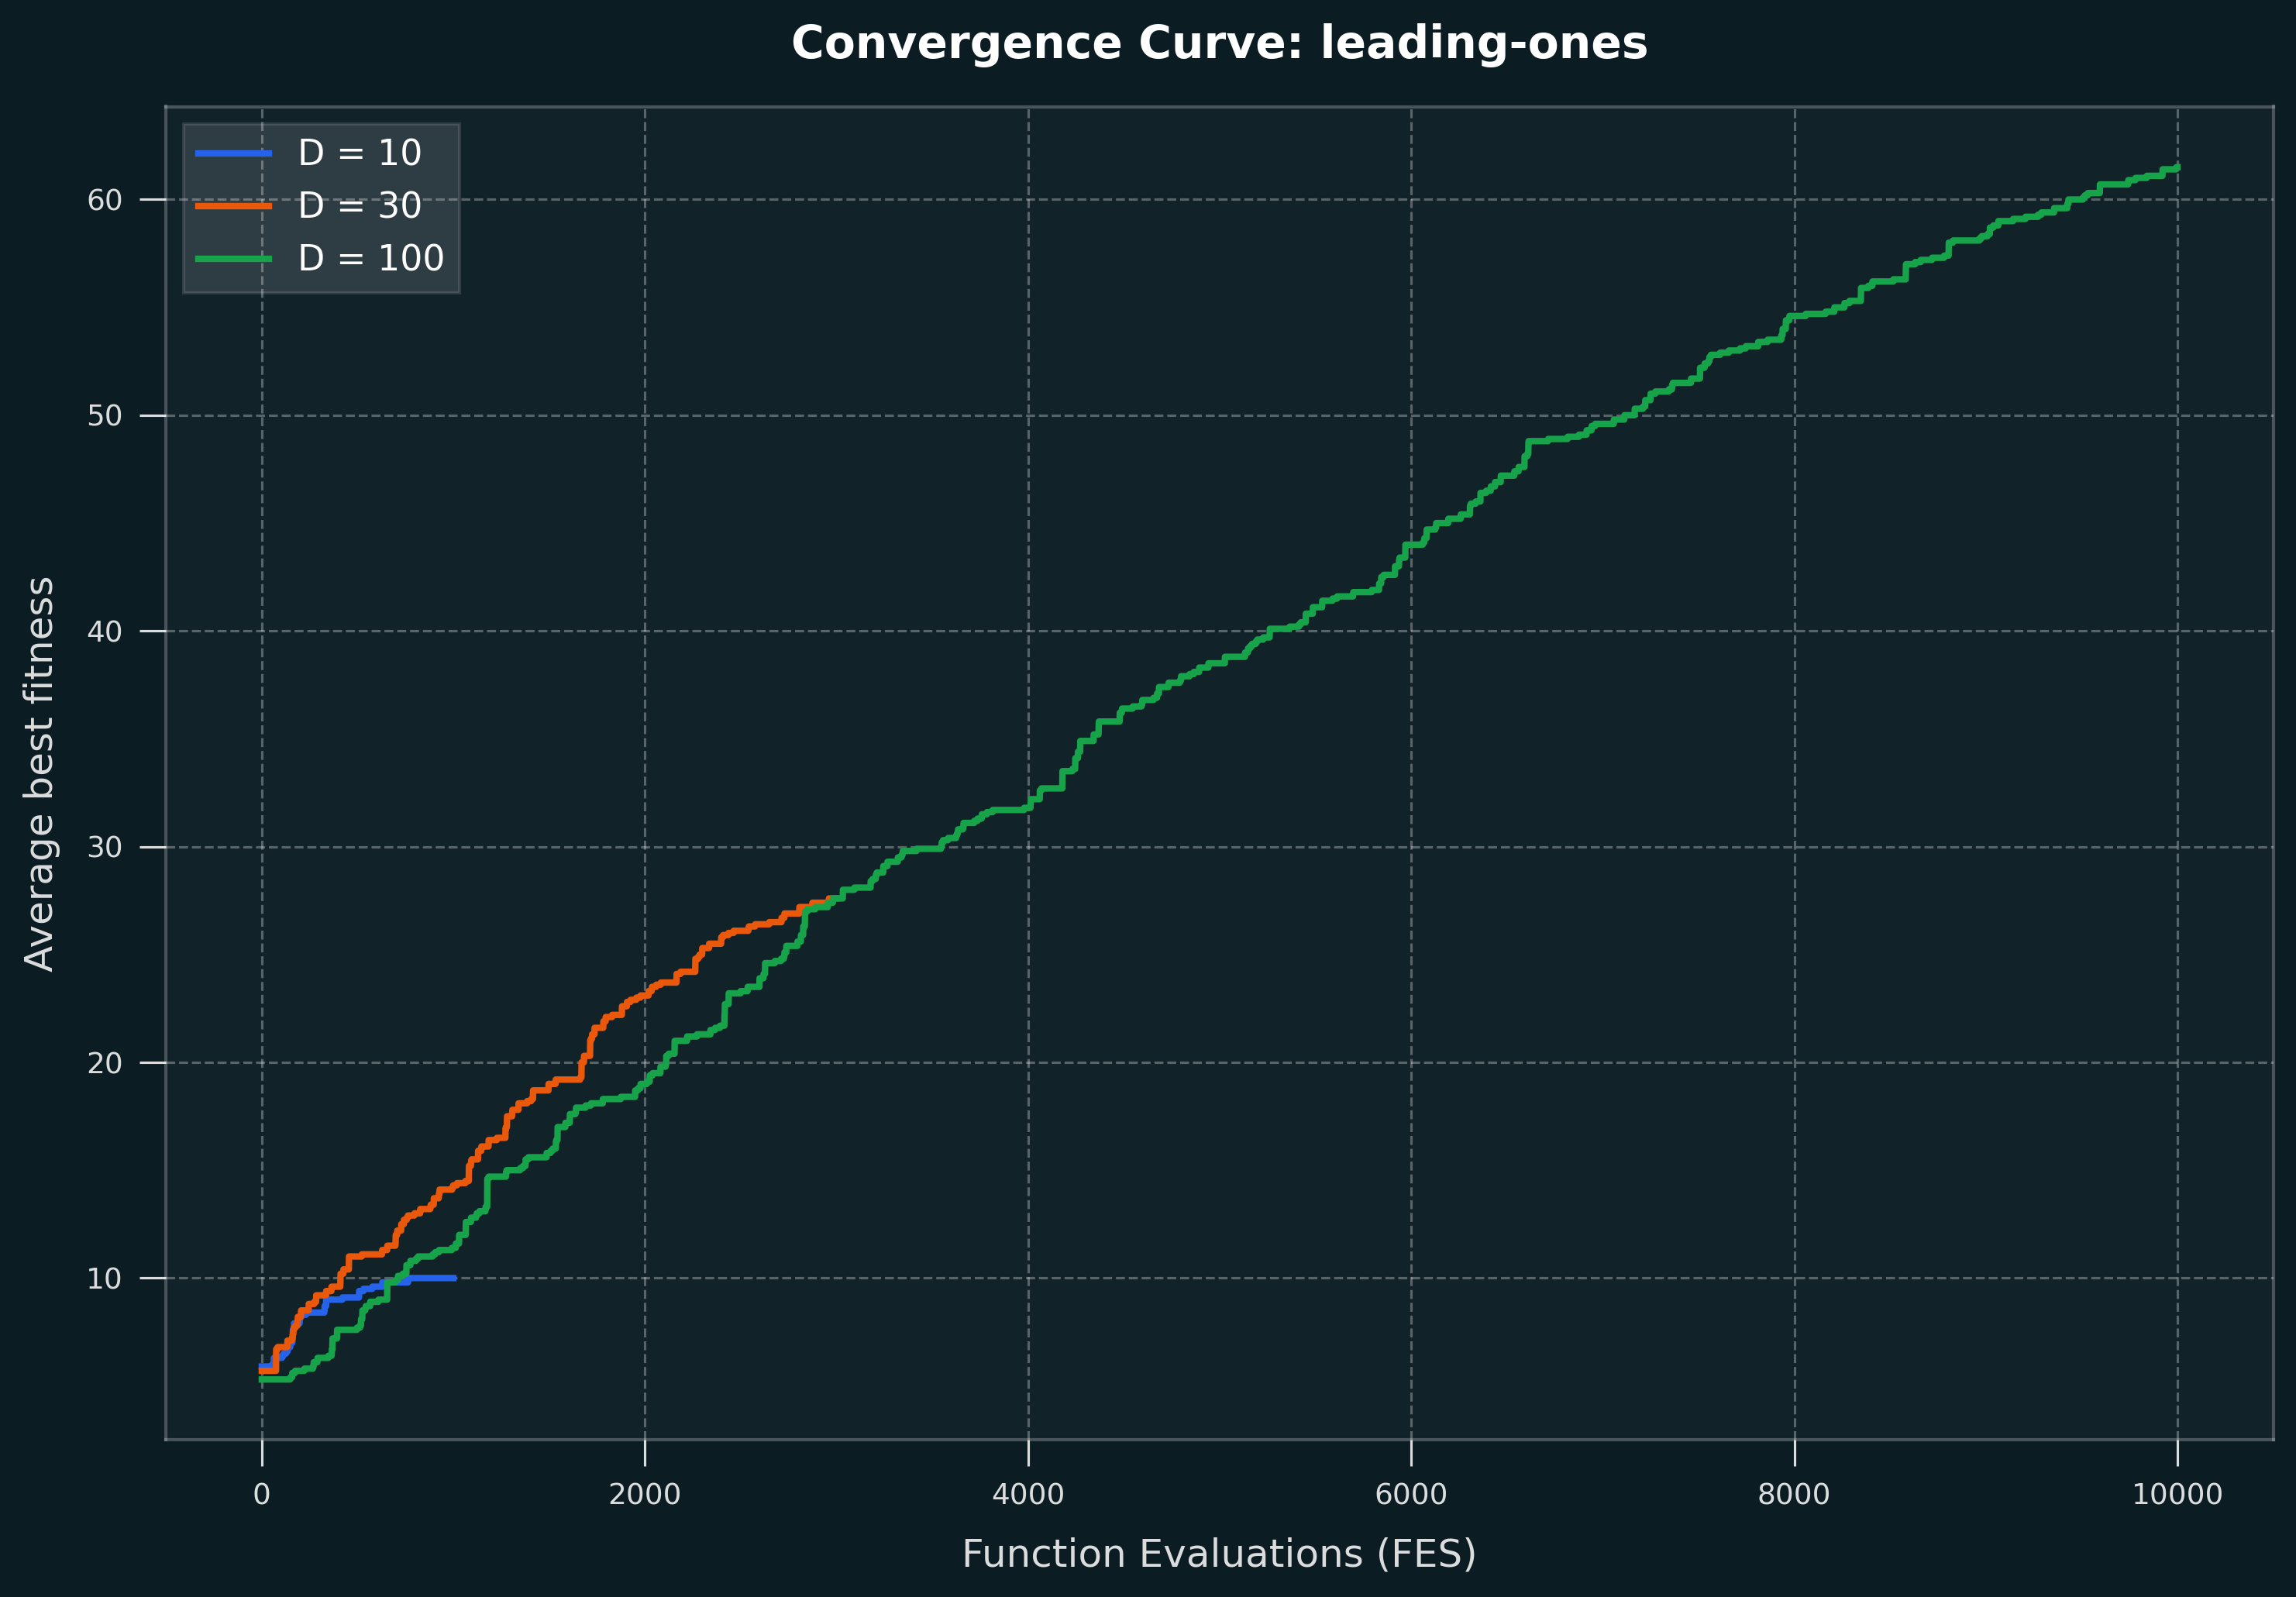

In [4]:
leading_ones_image = root / "img" / "convergence" / "convergence_leading-ones.png"
display(Image(filename=str(leading_ones_image), width=900))

**Explanation.** LeadingOnes improves in a staircase-like pattern. The `D = 10` curve reaches the optimum, and `D = 30` reaches approximately 28 on average. For `D = 100`, the curve is still increasing at 10,000 FES and finishes near 62, consistent with the final mean of 61.50. The larger variance in the 100-bit case reflects different rates at which runs repair the prefix.

## Comparison and conclusion

The same configuration solves One-Max reliably but scales less effectively on LeadingOnes. One-Max is separable: every bit contributes independently, so mutation and crossover can accumulate improvements anywhere. LeadingOnes is deceptive and positionally dependent: improving a later bit has no immediate objective benefit when an earlier zero remains. Single-point crossover can also disrupt a promising prefix, although 10% elitism protects the best individual.

In [5]:
comparison = summary.copy()
comparison["Optimal fitness"] = comparison["D"]
comparison["Mean / optimum"] = (
    comparison["mean"] / comparison["Optimal fitness"]
).round(3)
comparison[
    [
        "Problem",
        "D",
        "FES budget",
        "mean",
        "stddev",
        "Optimal fitness",
        "Mean / optimum",
    ]
]

,Problem,D,FES budget,mean,stddev,Optimal fitness,Mean / optimum
0,one-max,10,1000,10.0,0.00,10,1.000
1,one-max,30,3000,30.0,0.00,30,1.000
2,one-max,100,10000,100.0,0.00,100,1.000
3,leading-ones,10,1000,10.0,0.00,10,1.000
4,leading-ones,30,3000,27.6,3.72,30,0.920
5,leading-ones,100,10000,61.5,6.57,100,0.615
